# 10.3.2 Poço com gas lift

Poço vertical de 2048 m (5 in) em dois trechos: aresta 1 (líquido, 338 m, do
reservatório a 170 bar com IPL = 0.98 kg/s/bar) e aresta 2 (mistura, 1710 m,
padrão intermitente) até a choke de produção (Cv = 30, 10 bar). O gás de
elevação vem pela aresta 3 (linha de gás, 2 in, 1000 m, choke de gás Cv = 5) e
desce pelo anular (aresta 4, 1710 m) até o vértice dinâmico 8, que injeta no
tubing através de uma **válvula de retenção** (Cv = 5). Diferenças finitas
centrais; modelos monofásicos nas arestas 1, 3 e 4.

* Cenário 1 (sem intermitência): choke de gás 100 % → 75 % entre 100 e 150 s
  (Figuras 10.36–10.40).
* Cenário 2 (com intermitência): choke de gás 75 % → 15 % entre 100 e 150 s
  (Figuras 10.41–10.46). O suprimento de gás torna-se insuficiente e o poço
  passa a operar de forma intermitente.

Nota: a válvula de retenção foi regularizada (raiz quadrada suavizada em
ΔP → 0) para evitar o "chattering" que inviabiliza integradores com passo
adaptativo no regime intermitente; o arquivo do cenário 1 tem o vértice 8
gravado como estático, por isso a rede é tomada do arquivo do cenário 2 com a
tabela da choke do cenário 1.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from mfsim.notebook_utils import describe, run_case, compare_states, show_pipe, plot_elements, plot_vertices

## Cenário 2 - com intermitência (comparação direta com o MATLAB)

In [2]:
describe("10.3.2b")
case, raw, res = run_case("10.3.2b", rtol=1e-3, atol=1e-5)
compare_states(res, raw)

10.3.2 Poço com gas lift - cenário 2 (com intermitência)
Choke de gás 75%->15% entre 100 e 150 s.
Figuras da tese: Figs. 10.41-10.46


[implicit BDF] steps=342 rejected=58 rhs=14770 jac=473 | 9.3s
tempo de CPU: 9.26 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 liquid       PT        3.30e-03       4.16e-01   7.93e-03
   1 liquid       qL        3.04e-01       1.48e+01   2.05e-02
   2 beggs_brill  PT        3.90e-03       1.25e+00   3.12e-03
   2 beggs_brill  qL        3.99e-01       1.46e+01   2.73e-02
   2 beggs_brill  qG        2.90e-02       8.04e-01   3.61e-02
   3 gas          PT        3.15e-04       6.91e-02   4.56e-03
   3 gas          qG        1.07e-02       6.50e-01   1.64e-02
   4 gas          PT        1.69e-03       2.92e-01   5.79e-03
   4 gas          qG        2.74e-02       7.93e-01   3.45e-02
vértices dinâmicos: máx |dif| = [0.001      0.00170711]


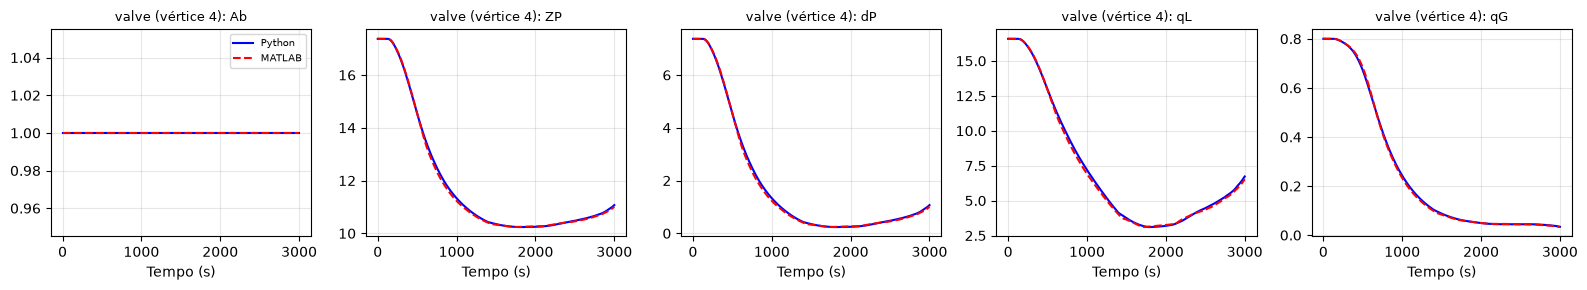

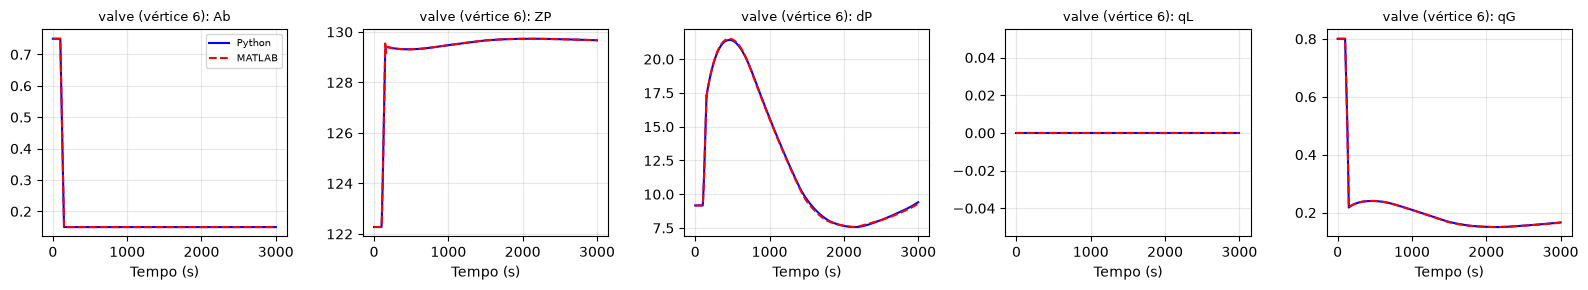

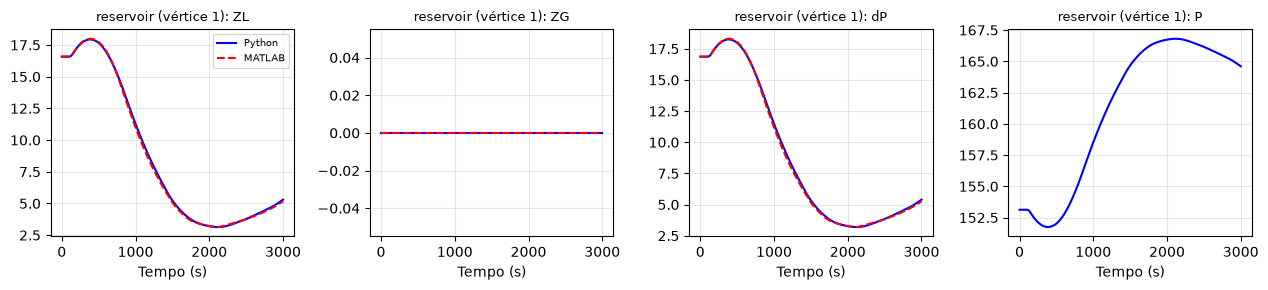

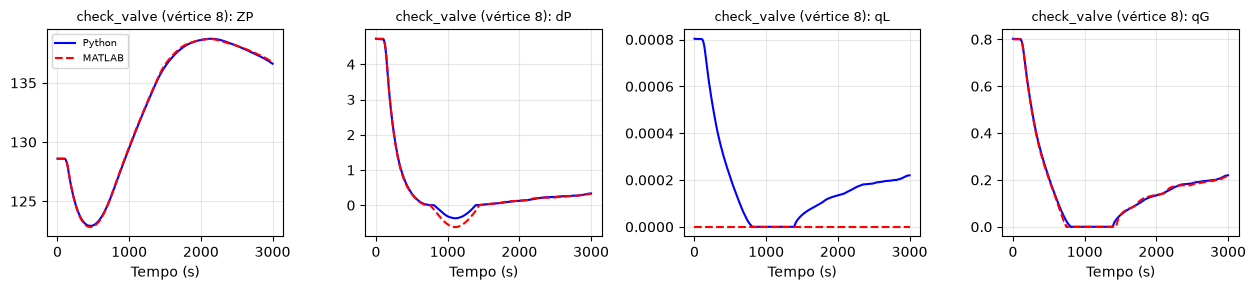

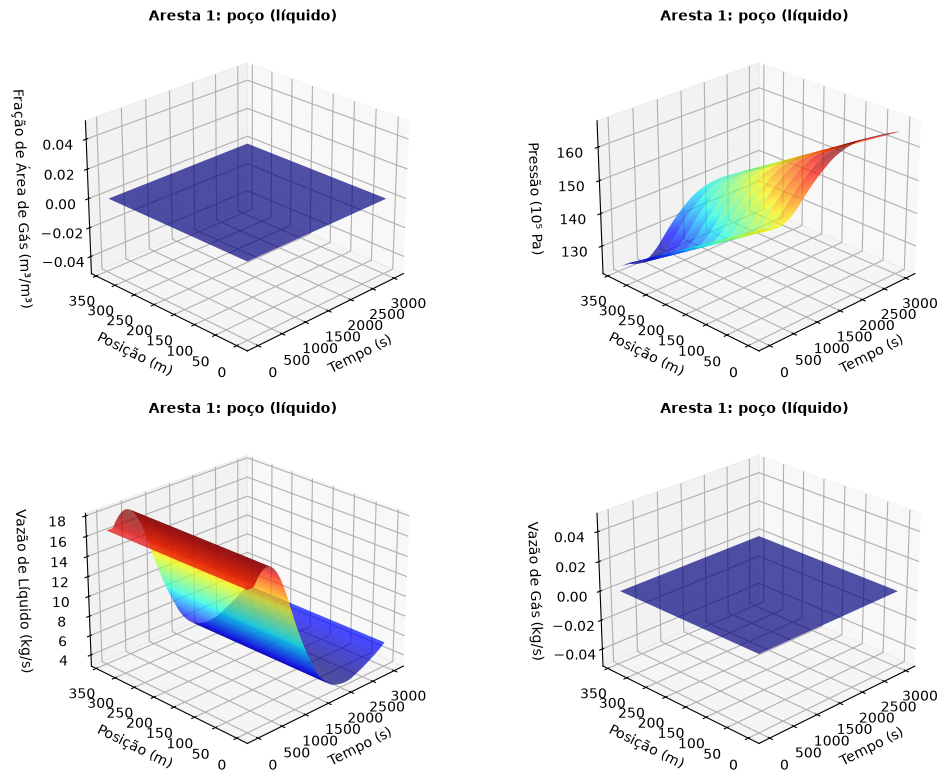

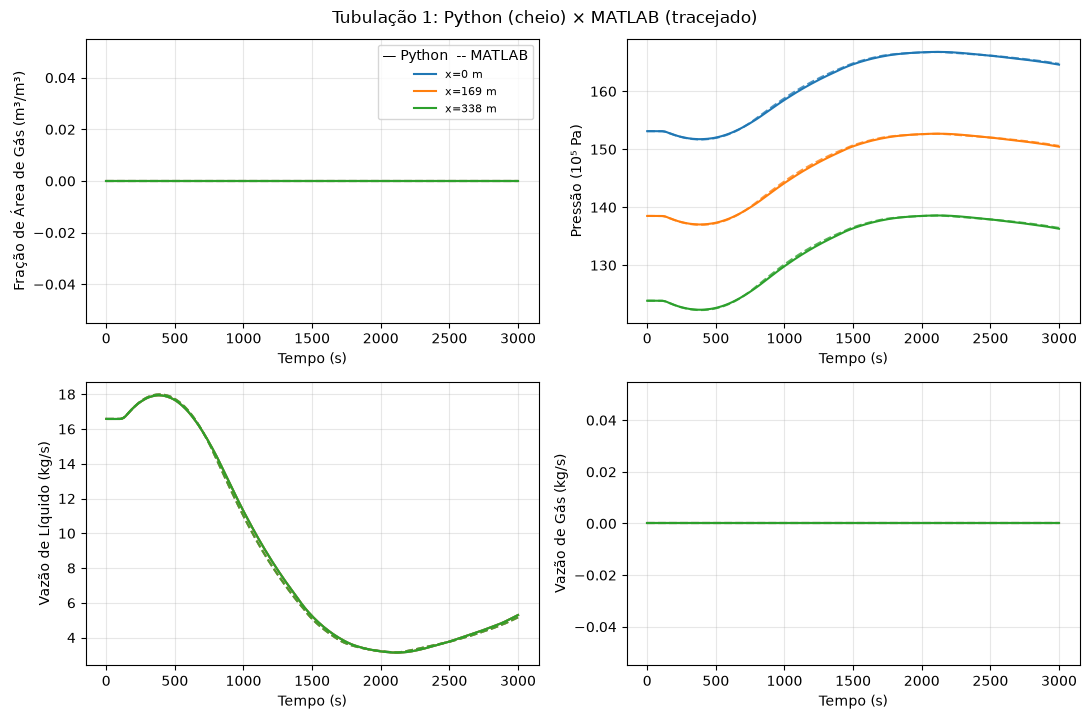

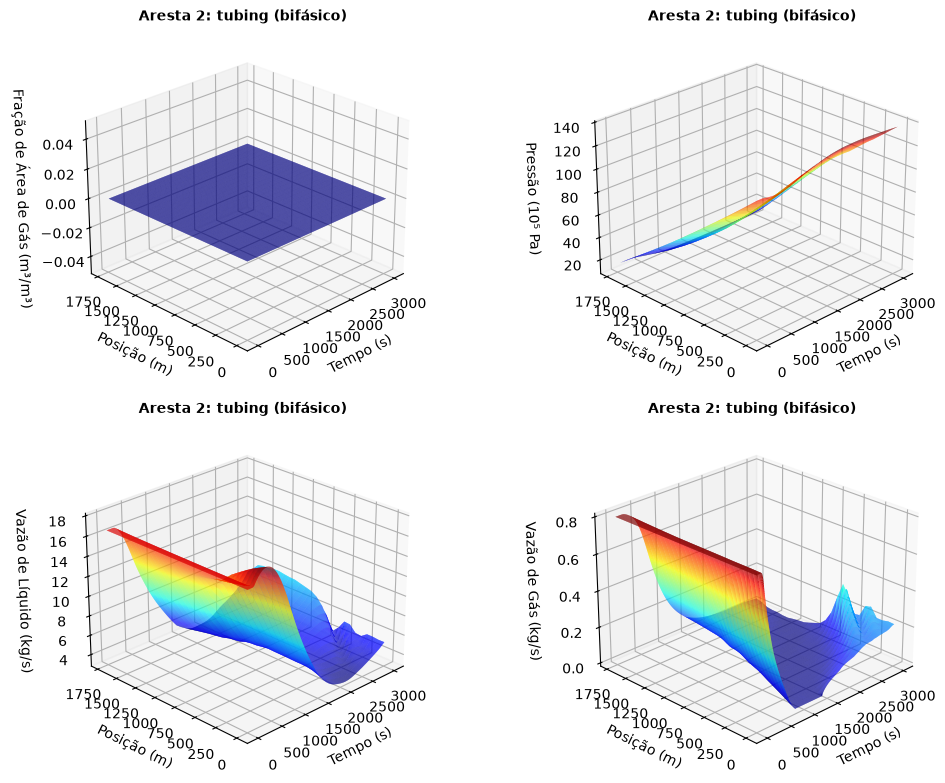

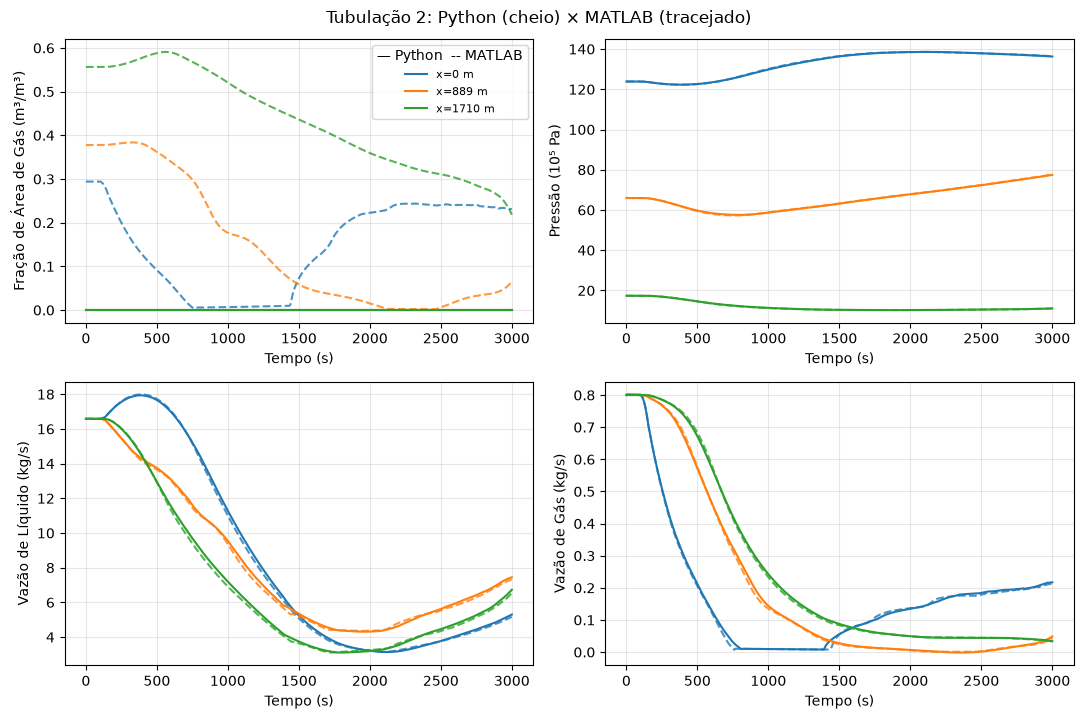

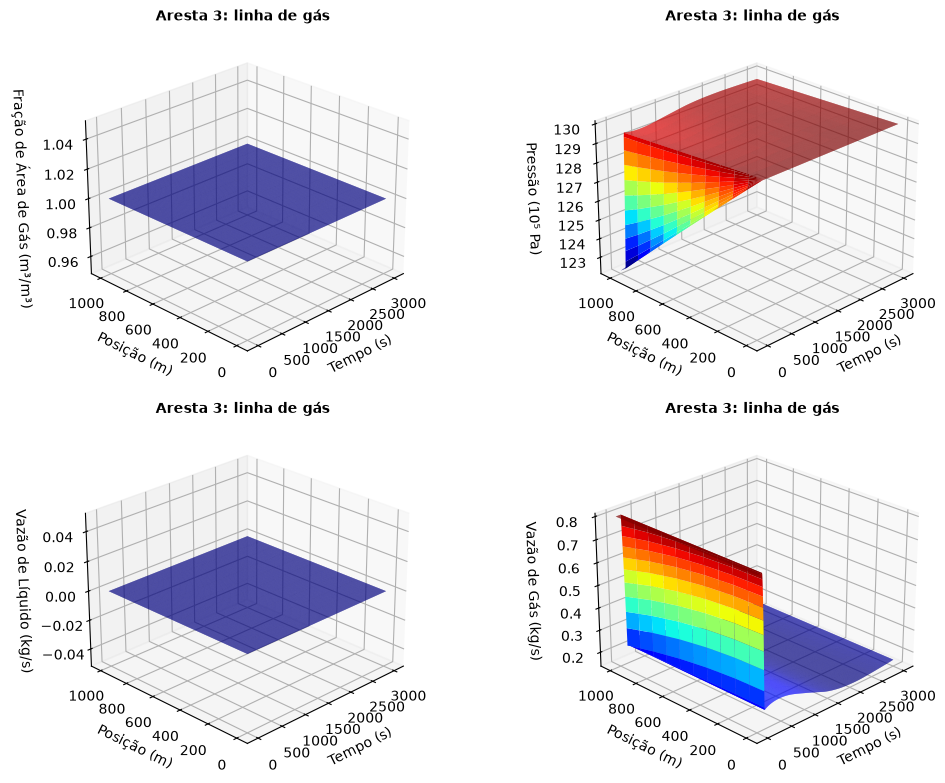

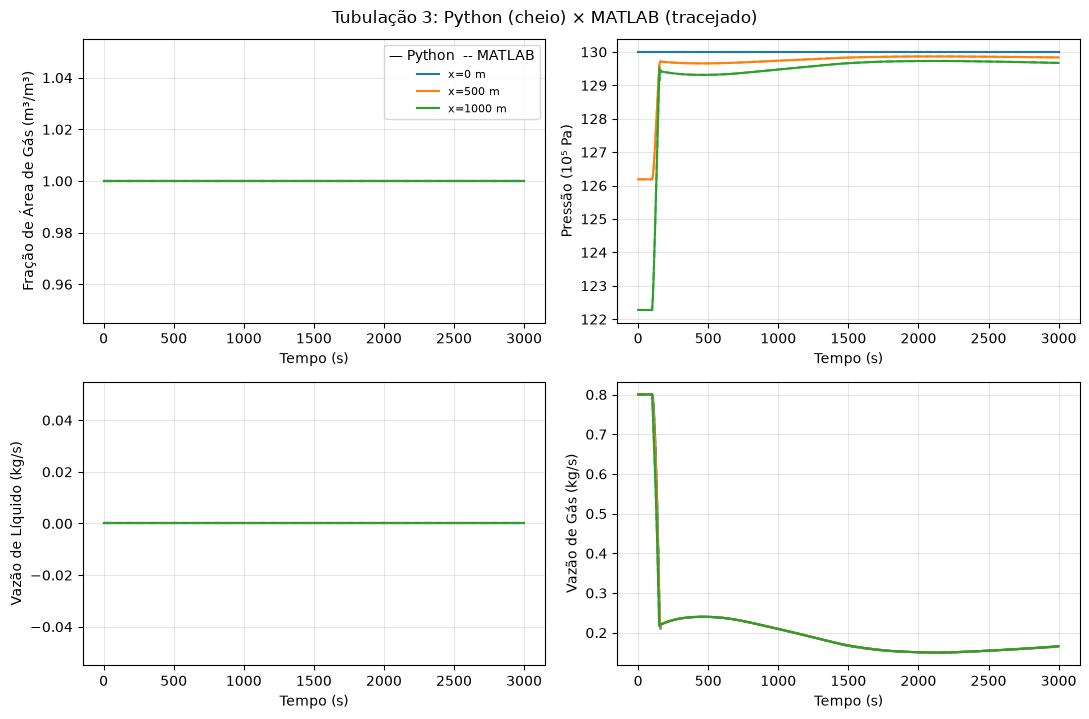

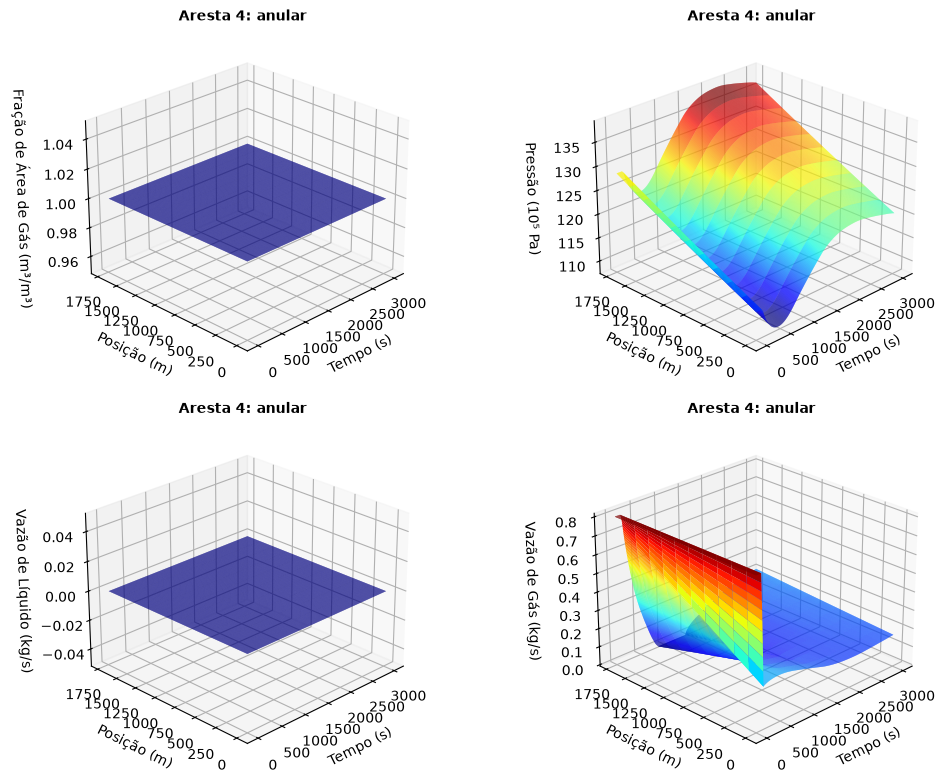

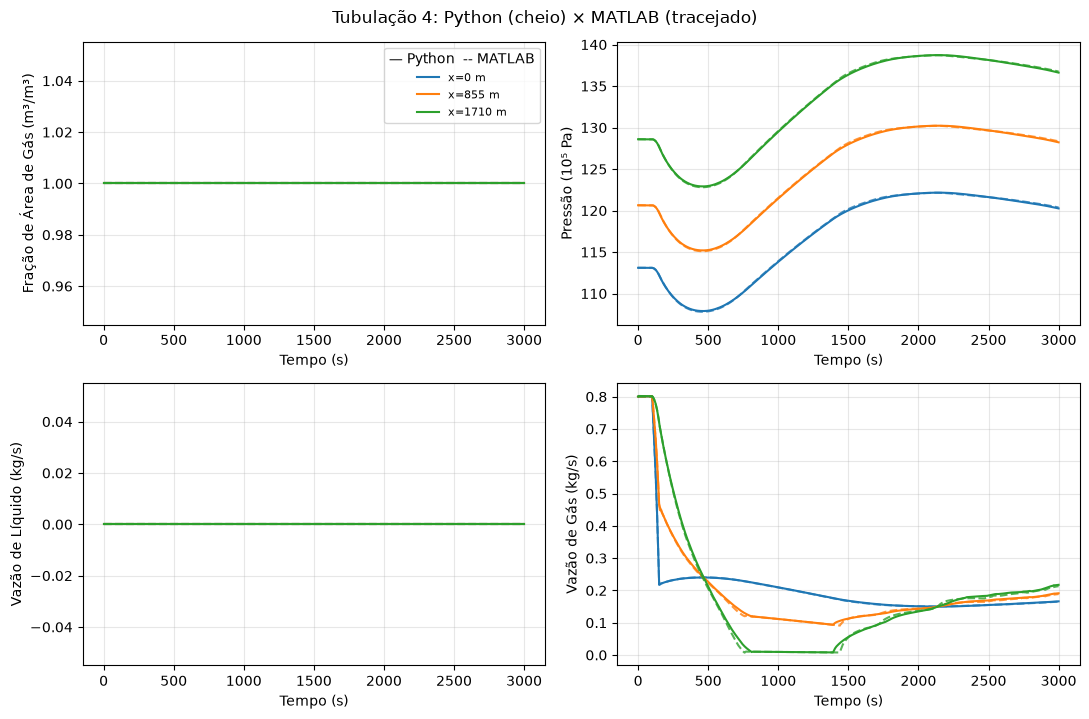

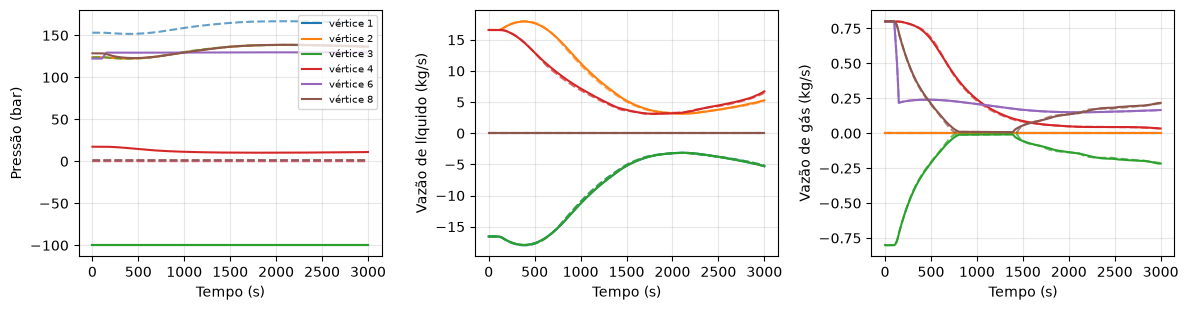

In [3]:
plot_elements(res, raw)
names = ["poço (líquido)", "tubing (bifásico)", "linha de gás", "anular"]
for k, nm in enumerate(names):
    show_pipe(res, raw, k, title=f"Aresta {k + 1}: {nm}")
plot_vertices(res, raw, indices=[1, 2, 3, 4, 6, 8])

## Cenário 1 - sem intermitência

10.3.2 Poço com gas lift - cenário 1 (sem intermitência)
Choke de gás 100%->75% entre 100 e 150 s.
Figuras da tese: Figs. 10.36-10.40


[implicit BDF] steps=95 rejected=10 rhs=1209 jac=29 | 0.7s
tempo de CPU: 0.73 s


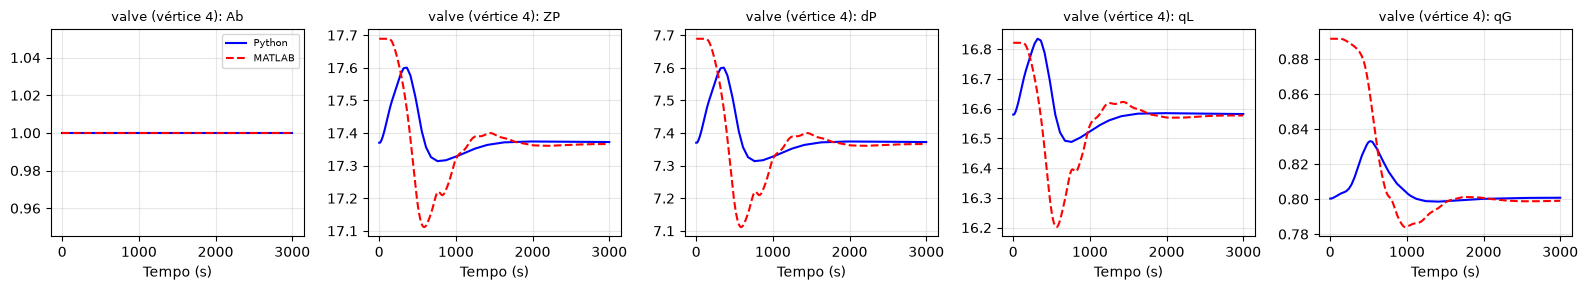

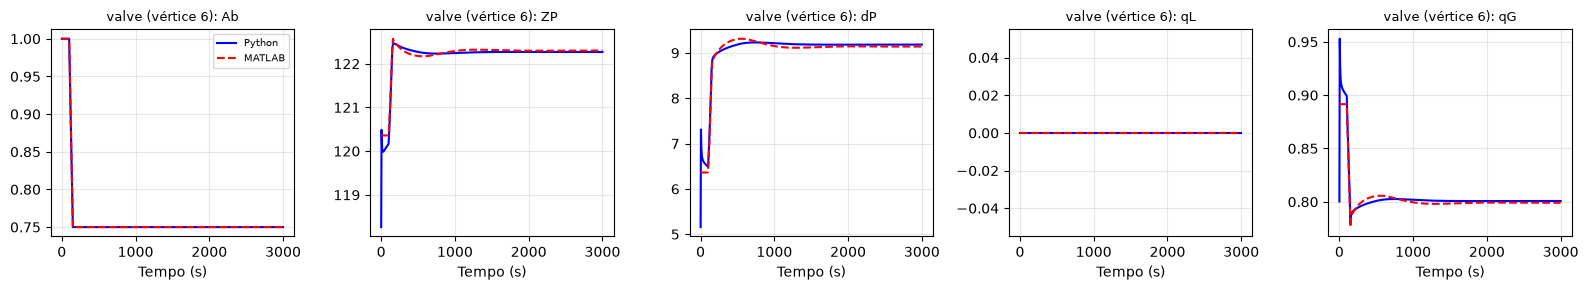

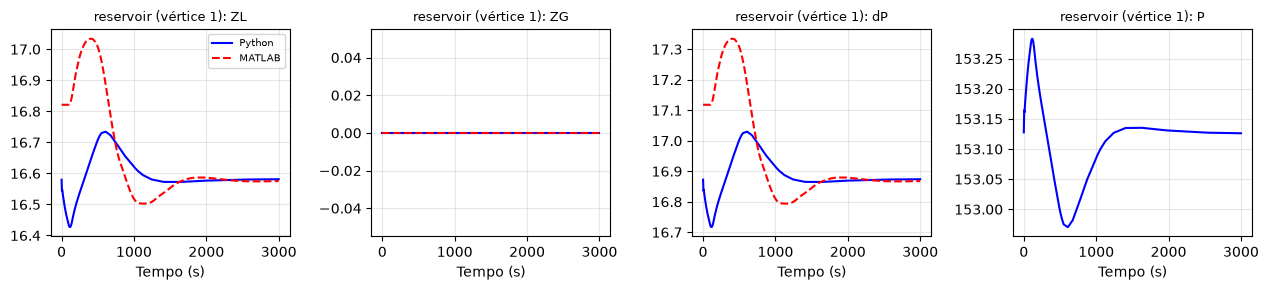

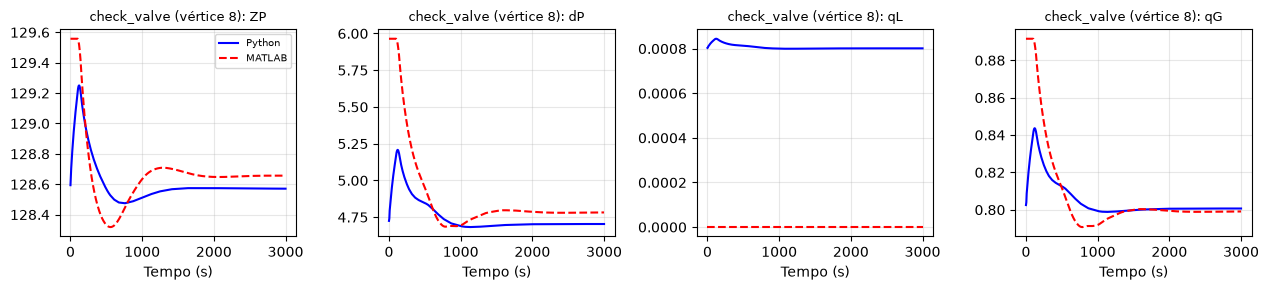

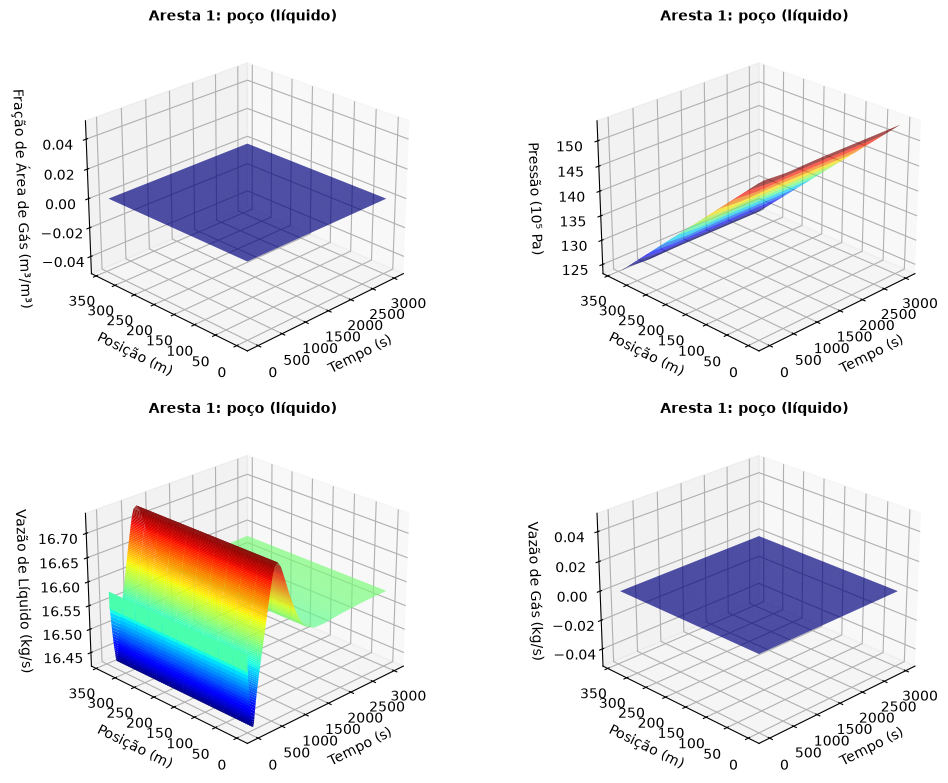

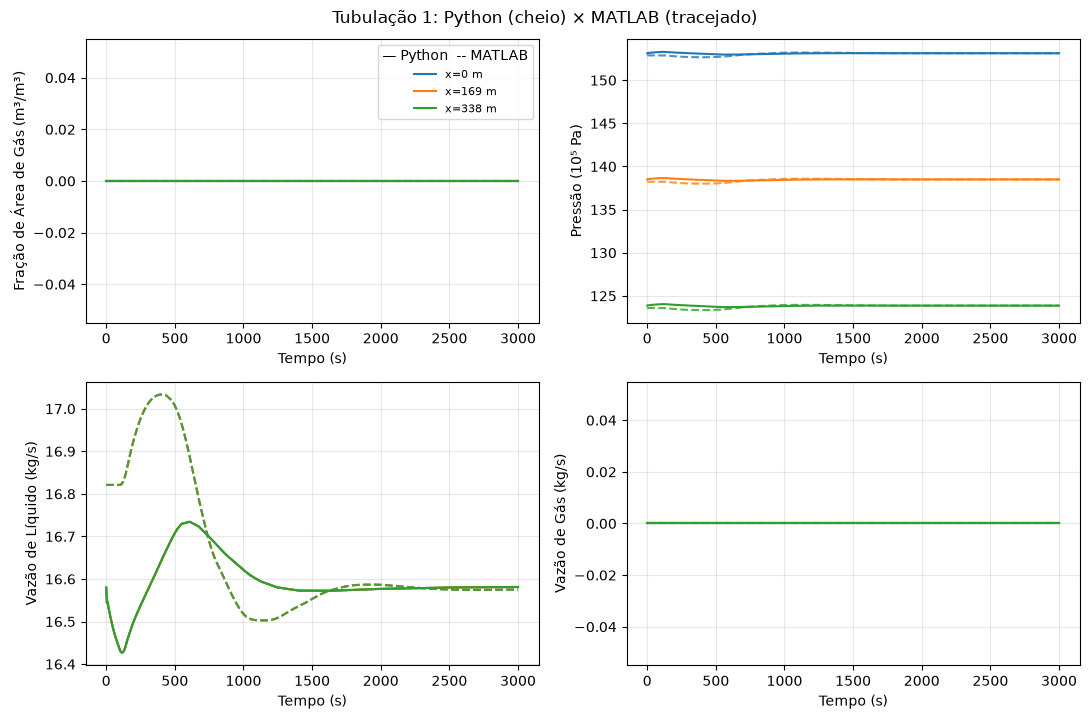

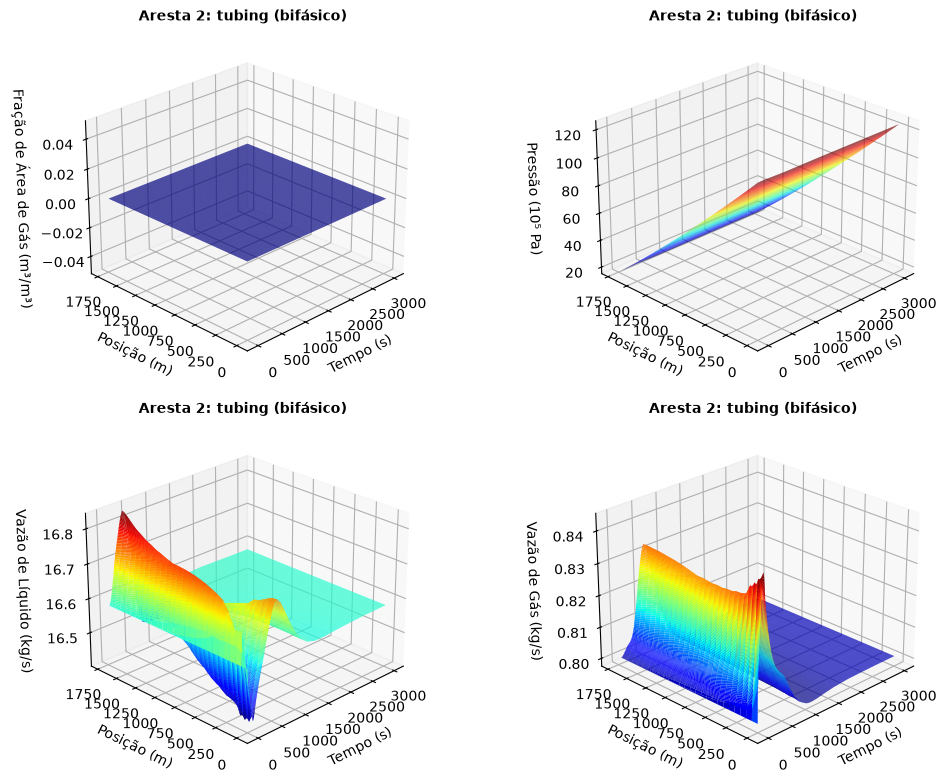

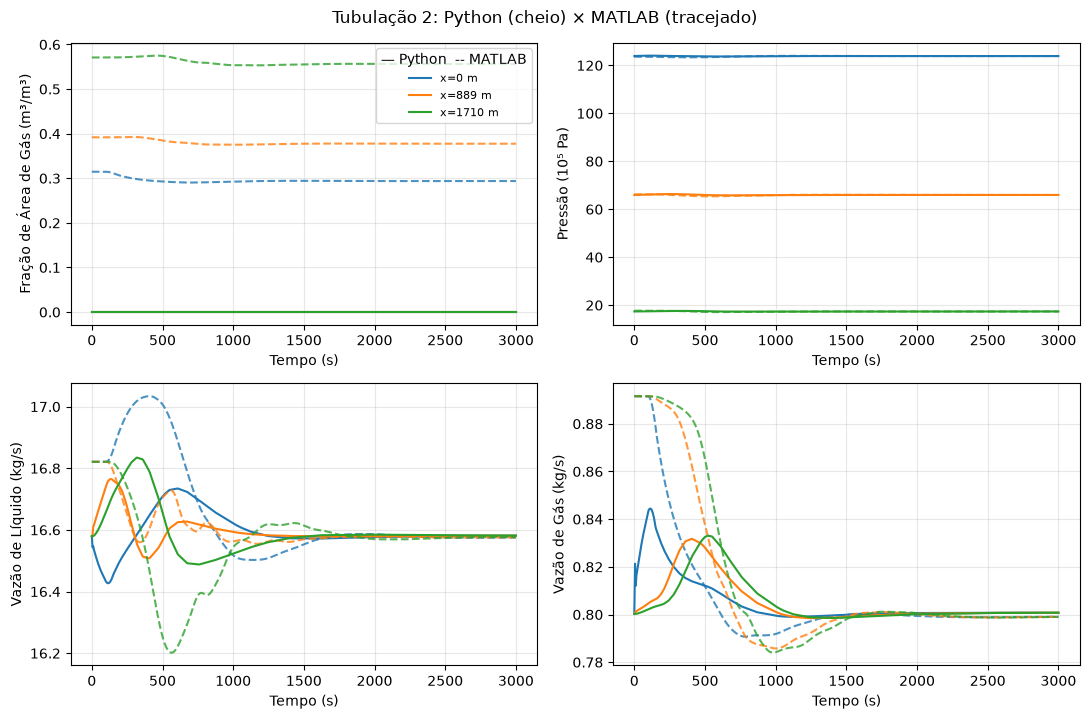

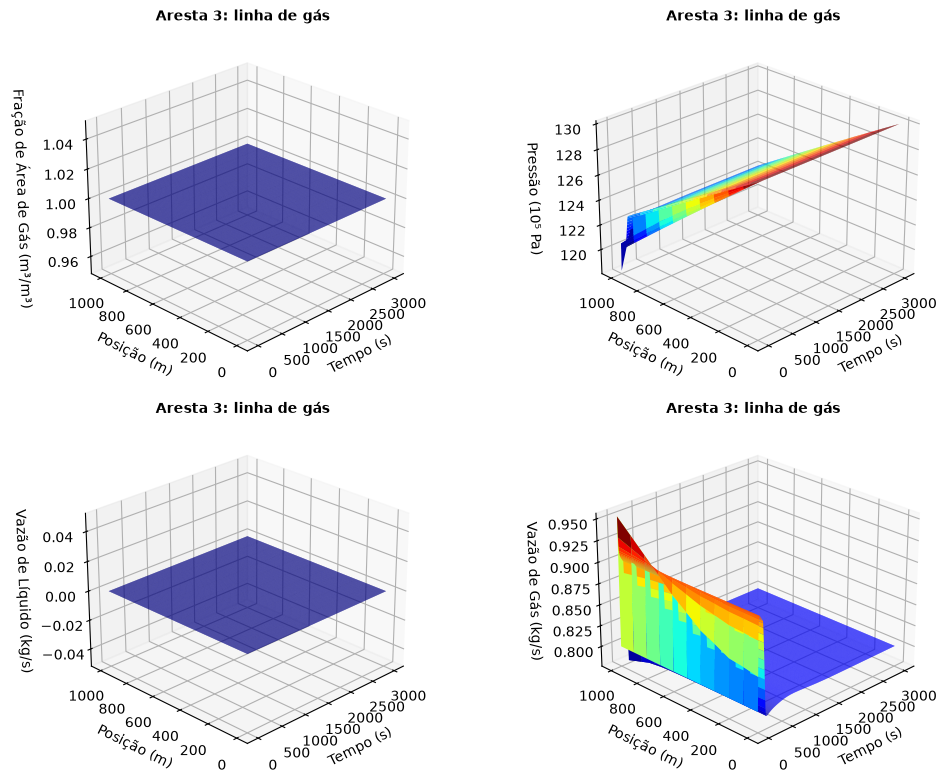

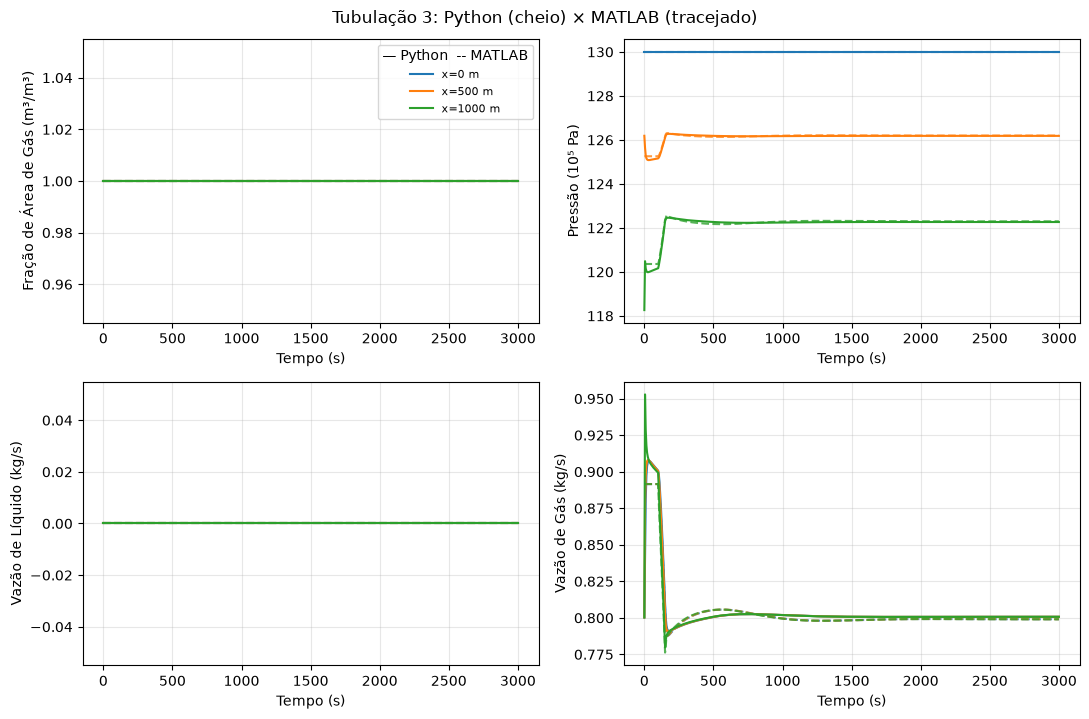

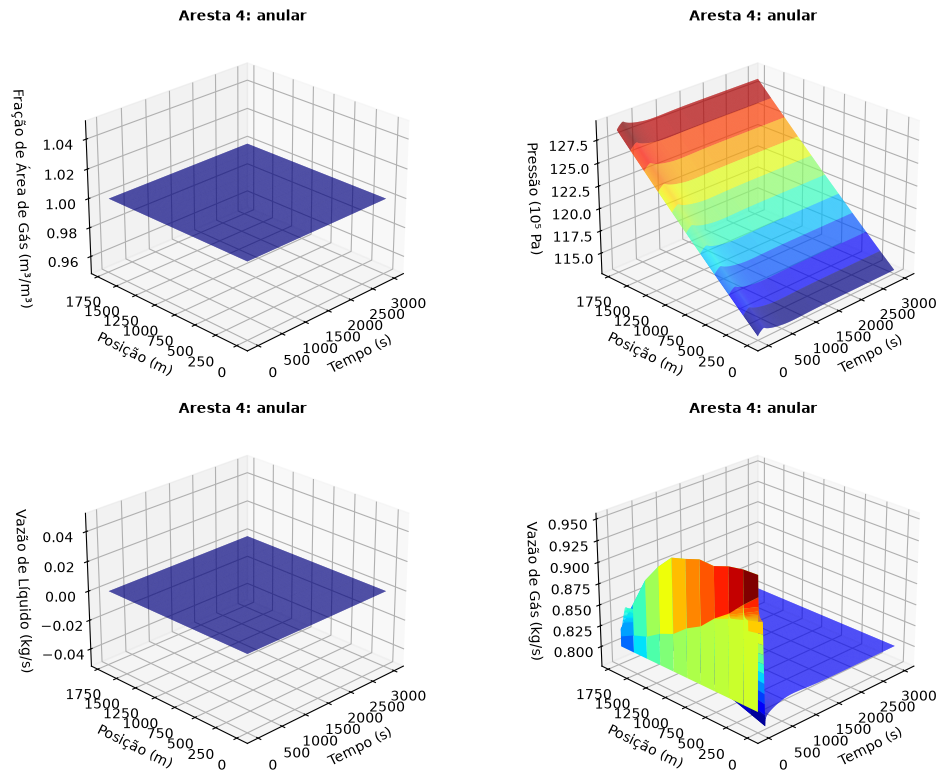

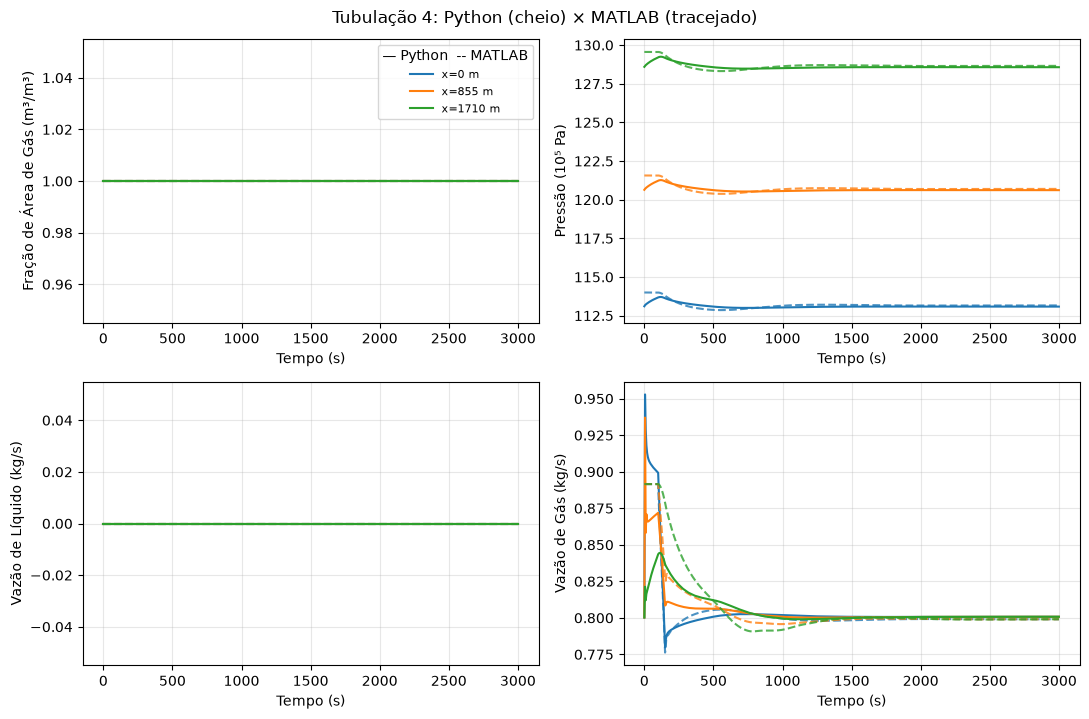

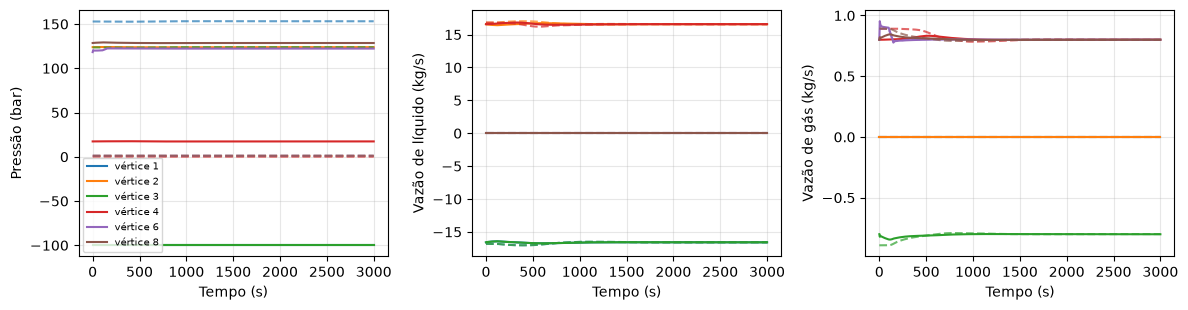

In [4]:
describe("10.3.2a")
case1, raw1, res1 = run_case("10.3.2a", rtol=1e-3, atol=1e-5)
plot_elements(res1, raw1)
for k, nm in enumerate(names):
    show_pipe(res1, raw1, k, title=f"Aresta {k + 1}: {nm}")
plot_vertices(res1, raw1, indices=[1, 2, 3, 4, 6, 8])

## Lado direito compilado (JAX)
A mesma simulação com `simulate(..., jax=True)`: lado direito compilado por
`jax.jit` e Jacobiana exata por diferenciação automática (`mfsim/compiled.py`, o mesmo código numpy com o backend JAX),
no lugar das diferenças finitas coloridas. O resultado deve coincidir com a versão
numpy dentro da tolerância do integrador (as sequências de passos podem diferir
porque a Jacobiana muda o Newton); o ganho de tempo cresce com o número de passos
e de Jacobianas.

In [5]:
from mfsim.notebook_utils import jax_comparison
res_jax = jax_comparison(case, res, rtol=1e-3, atol=1e-5)

JAX: 1.57 s (347 passos; compilação 1.06 s, uma vez por modelo) | numpy: 9.26 s (342 passos) | diferença máxima relativa dos estados 2.2e-02
